# BrushCue Example: Hexagonal Pixelate

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/hexagonal_pixelate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/hexagonal-pixelate

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


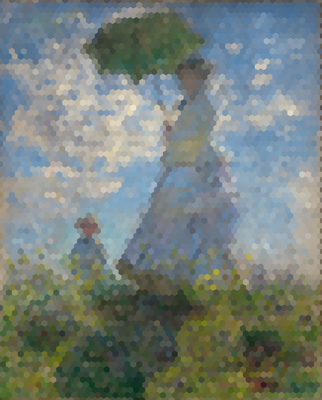

In [1]:
import io
from PIL import Image

import brushcue as bc

cell_size = 32.0
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
graph = input_image.spacial_effect_shader(
    "let size = cell_size * 0.57735027;\nlet lo = image_bounds.xy + vec2<f32>(0.5);\nlet hi = image_bounds.zw - vec2<f32>(0.5);\nlet center = hex_center(position - image_bounds.xy, size) + image_bounds.xy;\nvar total = sample(clamp(center, lo, hi));\nfor (var i = 0; i < 6; i = i + 1) {\n    let angle = f32(i) * 1.0471976 + 0.5235988;\n    let offset = vec2<f32>(cos(angle), sin(angle)) * size * 0.5;\n    total = total + sample(clamp(center + offset, lo, hi));\n}\nreturn total / 7.0;",
    "fn hex_center(p: vec2<f32>, size: f32) -> vec2<f32> {\n    let q = (0.57735027 * p.x - 0.33333333 * p.y) / size;\n    let r = (0.66666667 * p.y) / size;\n    let y = -q - r;\n    var rq = round(q);\n    var ry = round(y);\n    var rr = round(r);\n    let dq = abs(rq - q);\n    let dy = abs(ry - y);\n    let dr = abs(rr - r);\n    if (dq > dy && dq > dr) {\n        rq = -ry - rr;\n    } else if (dy <= dr) {\n        rr = -rq - ry;\n    }\n    return vec2<f32>(size * 1.7320508 * (rq + rr * 0.5), size * 1.5 * rr);\n}",
    cell_size,
    bc.Dictionary.create()
    .add("cell_size", cell_size)
    .add("image_bounds", input_bounds),
    bc.ColorRepresentation.srgb(),
).crop(input_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
